# Calibration Analysis

This notebook reads the responses saved by `run_experiment.py` and measures how well each model's confidence matches its accuracy.

Two confidence measures are compared for each question.

* **Verbalized confidence** is the number the model states alongside its temperature 0 answer.
* **Consistency** is the share of the sampled answers (temperature 0.7) that agree with the temperature 0 answer.

A well calibrated model is right about 80% of the time on the questions where it reports 80% confidence.

In [1]:
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import pandas as pd

from calibration.metrics import bootstrap_ci, reliability_table, summarize
from calibration.prompts import shuffled_choices

RESULTS_DIR = pathlib.Path("results/raw")   # change to results/dry_run to view the simulated test
FIGURES_DIR = pathlib.Path("results/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
N_BINS = 10

# Soft gem tones, checked for colorblind safety and contrast
COLORS = {"accuracy": "#2f9a74",      # emerald
          "verbalized": "#4a7fd0",    # sapphire
          "consistency": "#c9607e"}   # rose garnet
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10,
})
pd.set_option("display.max_colwidth", 120)

## Load responses

In [2]:
files = sorted(RESULTS_DIR.glob("*.jsonl"))
if not files:
    raise FileNotFoundError(f"No results in {RESULTS_DIR}. Run run_experiment.py first.")

raw = pd.concat([pd.read_json(f, lines=True) for f in files], ignore_index=True)
questions = {q["id"]: q for q in map(json.loads, open("data/questions.jsonl"))}

overview = raw.groupby("model").agg(
    responses=("question_id", "size"),
    questions=("question_id", "nunique"),
    parse_rate=("parsed", "mean"),
    confidence_given=("confidence", lambda c: c.notna().mean()),
)
overview

,responses,questions,parse_rate,confidence_given
model,,,,
Qwen/Qwen3.5-9B,390,65,1.0,1.000000
meta-llama/Llama-3.3-70B-Instruct-Turbo,390,65,1.0,0.997436


## One row per question

For each model and question this builds the main answer (temperature 0), whether it was correct, the stated confidence, and the consistency of the sampled answers. A sample with no readable answer counts as disagreeing.

In [3]:
def per_question(df):
    main = df[df["sample"] == 0].set_index("question_id")
    samples = df[df["sample"] > 0]
    rows = []
    for qid, m in main.iterrows():
        s = samples[samples["question_id"] == qid]
        agree = (s["answer"] == m["answer"]).mean() if (len(s) and m["parsed"]) else np.nan
        rows.append({
            "question_id": qid, "topic": m["topic"], "difficulty": m["difficulty"],
            "answer": m["answer"], "correct_letter": m["correct_letter"],
            "correct": bool(m["correct"]), "verbalized": m["confidence"],
            "consistency": agree, "n_samples": len(s),
        })
    return pd.DataFrame(rows)

tables = {model: per_question(df) for model, df in raw.groupby("model")}
for model, t in tables.items():
    missing_v = t["verbalized"].isna().sum()
    missing_c = t["consistency"].isna().sum()
    print(f"{model}: {len(t)} questions, accuracy {t['correct'].mean():.1%}, "
          f"{missing_v} without stated confidence, {missing_c} without consistency")

Qwen/Qwen3.5-9B: 65 questions, accuracy 100.0%, 0 without stated confidence, 0 without consistency
meta-llama/Llama-3.3-70B-Instruct-Turbo: 65 questions, accuracy 98.5%, 0 without stated confidence, 0 without consistency


## Calibration metrics

* **Accuracy** is the share of main answers that are correct.
* **Overconfidence** is mean confidence minus accuracy. Positive means the model claims more than it delivers.
* **Brier score** is the mean squared error of the confidence (lower is better).
* **ECE** (expected calibration error) is the average gap between confidence and accuracy across 10 confidence bins, weighted by bin size (lower is better).
* **AUROC** is the probability that a correct answer received higher confidence than a wrong one. 0.5 means confidence carries no information about correctness.

Brackets are 95% bootstrap intervals from resampling questions. With about 65 questions they are wide, so treat small differences with caution.

In [4]:
METHODS = ["verbalized", "consistency"]
summary_rows = []
for model, t in tables.items():
    for method in METHODS:
        d = t.dropna(subset=[method])
        s = summarize(d[method], d["correct"].astype(int), N_BINS)
        ci = bootstrap_ci(d[method], d["correct"].astype(int), n_boot=2000, n_bins=N_BINS)
        row = {"model": model, "method": method, "n": s["n"]}
        for k in ["accuracy", "mean_confidence", "overconfidence", "brier", "ece", "auroc"]:
            if np.isnan(s[k]):
                row[k] = "undefined (no wrong answers)" if d["correct"].all() else "undefined"
            else:
                row[k] = f"{s[k]:.3f} [{ci[k][0]:.3f}, {ci[k][1]:.3f}]"
        summary_rows.append(row)

summary = pd.DataFrame(summary_rows).set_index(["model", "method"])
summary.to_csv(FIGURES_DIR.parent / "summary_metrics.csv")
summary

n              accuracy  \
model                                   method                                  
Qwen/Qwen3.5-9B                         verbalized   65  1.000 [1.000, 1.000]   
                                        consistency  65  1.000 [1.000, 1.000]   
meta-llama/Llama-3.3-70B-Instruct-Turbo verbalized   65  0.985 [0.954, 1.000]   
                                        consistency  65  0.985 [0.954, 1.000]   

                                                          mean_confidence  \
model                                   method                              
Qwen/Qwen3.5-9B                         verbalized   0.998 [0.995, 1.000]   
                                        consistency  1.000 [1.000, 1.000]   
meta-llama/Llama-3.3-70B-Instruct-Turbo verbalized   0.998 [0.994, 1.000]   
                                        consistency  0.942 [0.898, 0.975]   

                                                              overconfidence  \
model                                   method                                 
Qwen/Qwen3.5-9B                         verbalized    -0.002 [-0.005, 0.000]   
                                        consistency     0.000 [0.000, 0.000]   
meta-llama/Llama-3.3-70B-Instruct-Turbo verbalized     0.013 [-0.005, 0.045]   
                                        consistency  -0.043 [-0.083, -0.006]   

                                                                    brier  \
model                                   method                              
Qwen/Qwen3.5-9B                         verbalized   0.000 [0.000, 0.000]   
                                        consistency  0.000 [0.000, 0.000]   
meta-llama/Llama-3.3-70B-Instruct-Turbo verbalized   0.016 [0.000, 0.046]   
                                        consistency  0.026 [0.009, 0.047]   

                                                                      ece  \
model                                   method                              
Qwen/Qwen3.5-9B                         verbalized   0.002 [0.000, 0.005]   
                                        consistency  0.000 [0.000, 0.000]   
meta-llama/Llama-3.3-70B-Instruct-Turbo verbalized   0.013 [0.001, 0.045]   
                                        consistency  0.043 [0.015, 0.083]   

                                                                            auroc  
model                                   method                                     
Qwen/Qwen3.5-9B                         verbalized   undefined (no wrong answers)  
                                        consistency  undefined (no wrong answers)  
meta-llama/Llama-3.3-70B-Instruct-Turbo verbalized           0.469 [0.438, 0.492]  
                                        consistency          0.977 [0.945, 1.000]

## Reliability diagrams

Each point is a confidence bin. Its position shows the average confidence and the actual accuracy in that bin, and its size shows how many questions fall in it. Points below the diagonal are overconfident. The bars underneath show how confidence is distributed.

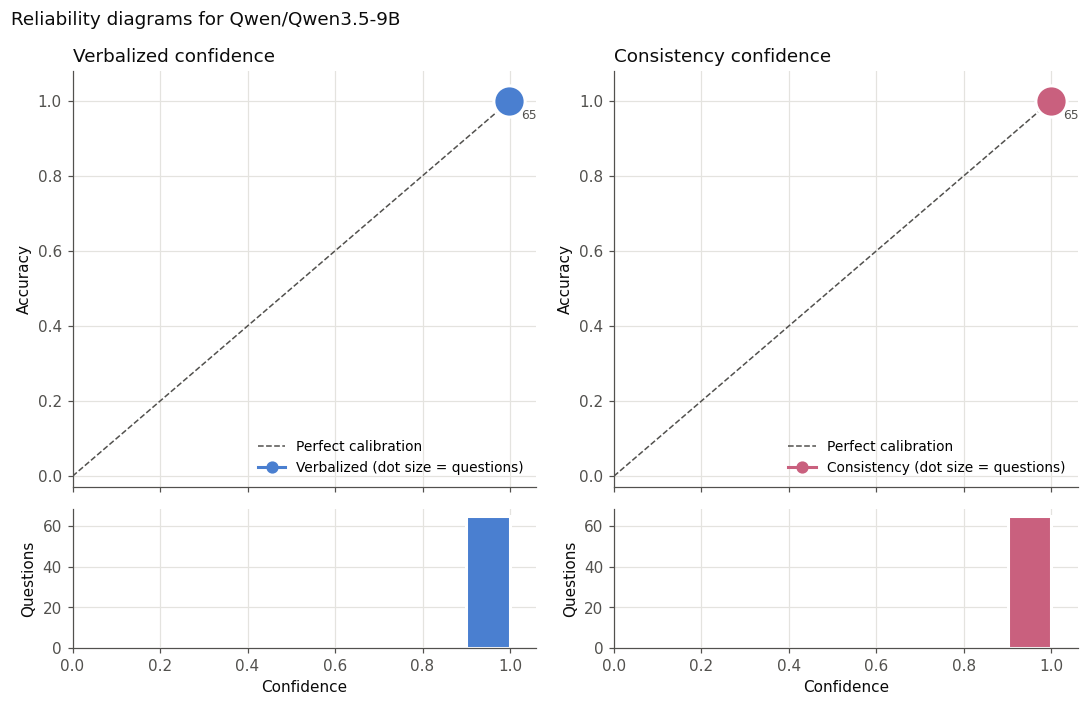

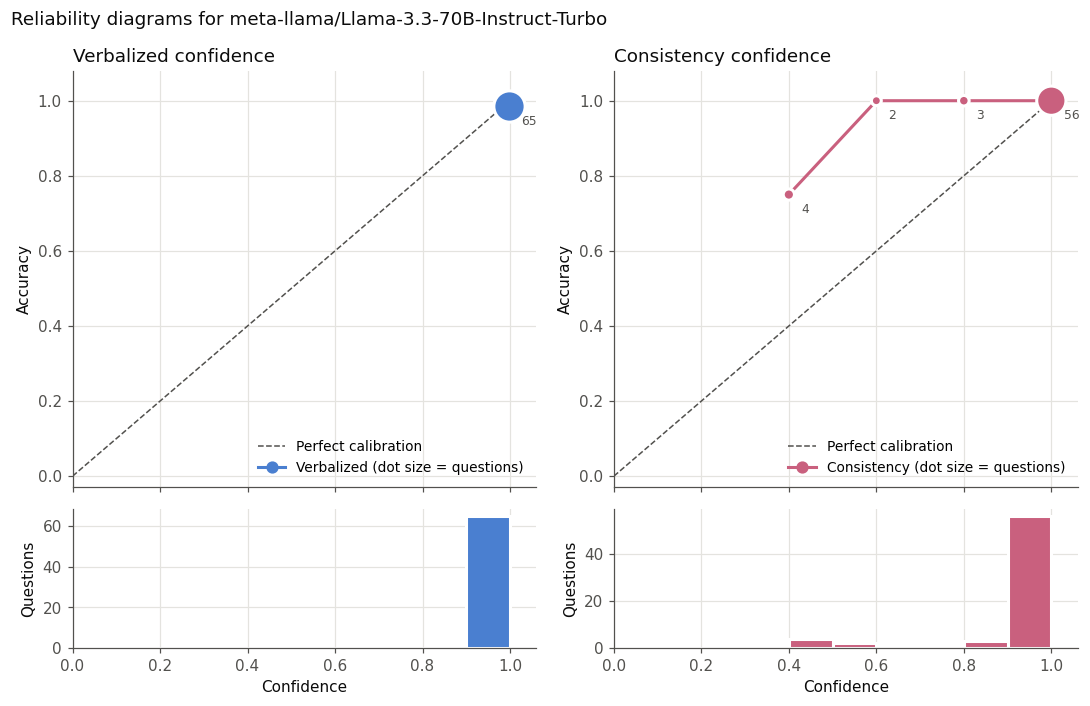

In [5]:
def reliability_plot(t, model):
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1]})
    for col, method in enumerate(METHODS):
        d = t.dropna(subset=[method])
        rows = reliability_table(d[method], d["correct"].astype(int), N_BINS)
        ax, hist = axes[0, col], axes[1, col]
        ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
        x = [r["mean_confidence"] for r in rows]
        y = [r["accuracy"] for r in rows]
        n = [r["count"] for r in rows]
        ax.plot(x, y, color=COLORS[method], linewidth=2)
        ax.scatter(x, y, s=[30 + 6 * k for k in n], color=COLORS[method],
                   edgecolor="white", linewidth=2, zorder=3, clip_on=False)
        for xi, yi, k in zip(x, y, n):
            ax.annotate(str(k), (xi, yi), textcoords="offset points", xytext=(8, -12),
                        fontsize=8, color=MUTED)
        ax.set_xlim(0, 1.06)
        ax.set_ylim(-0.03, 1.08)
        ax.set_ylabel("Accuracy")
        ax.set_title(f"{method.capitalize()} confidence", color=INK, loc="left")
        # Legend with a normal-sized marker (dot size in the plot shows question count)
        handles = [Line2D([0], [0], color=MUTED, linestyle="--", linewidth=1, label="Perfect calibration"),
                   Line2D([0], [0], color=COLORS[method], marker="o", markersize=7, linewidth=2,
                          label=f"{method.capitalize()} (dot size = questions)")]
        ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=9)

        hist.set_xlim(0, 1.06)
        hist.hist(d[method], bins=np.linspace(0, 1, N_BINS + 1), color=COLORS[method],
                  edgecolor="white", linewidth=2)
        hist.set_xlabel("Confidence")
        hist.set_ylabel("Questions")
    fig.suptitle(f"Reliability diagrams for {model}", x=0.01, ha="left", color=INK)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"reliability_{model.split('/')[-1]}.png", bbox_inches="tight")
    plt.show()

for model, t in tables.items():
    reliability_plot(t, model)

## Accuracy and confidence by difficulty

Difficulty labels were assigned by the question author before any model was run. A common finding is that models stay confident as questions get harder while their accuracy drops.

,accuracy,verbalized,consistency,questions
difficulty,,,,
easy,1.0,1.000,1.0,20
medium,1.0,1.000,1.0,22
hard,1.0,0.993,1.0,23


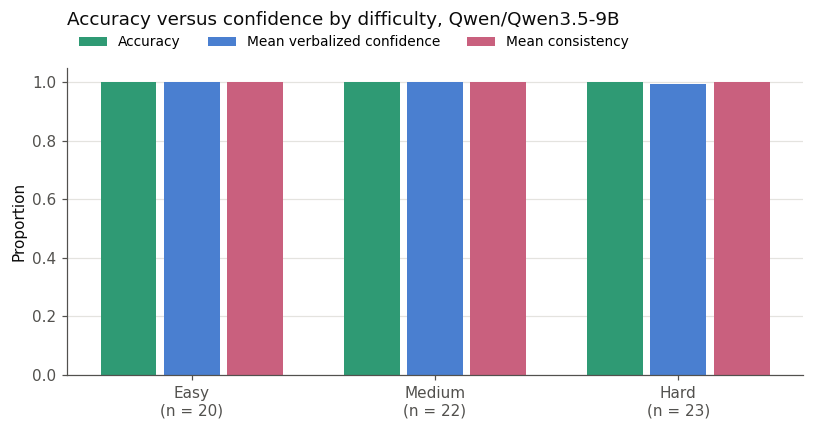

,accuracy,verbalized,consistency,questions
difficulty,,,,
easy,1.000,1.000,0.990,20
medium,1.000,0.998,0.955,22
hard,0.957,0.995,0.887,23


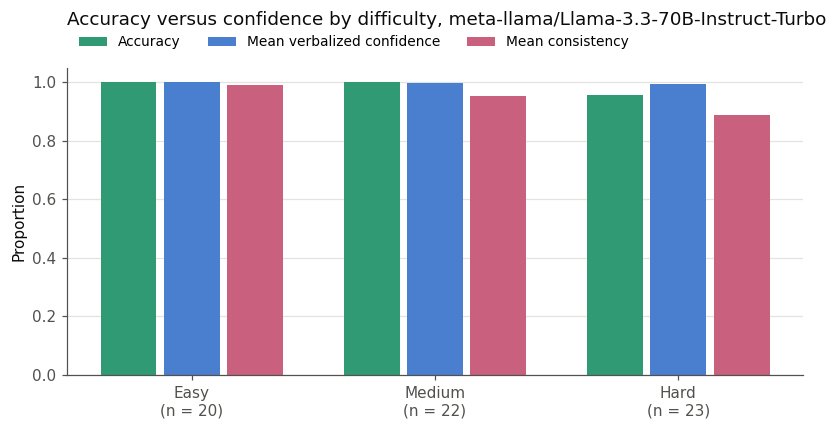

In [6]:
order = ["easy", "medium", "hard"]
for model, t in tables.items():
    g = t.groupby("difficulty").agg(
        accuracy=("correct", "mean"),
        verbalized=("verbalized", "mean"),
        consistency=("consistency", "mean"),
        questions=("question_id", "size"),
    ).reindex(order)
    display(g.round(3))

    fig, ax = plt.subplots(figsize=(7.5, 4))
    width = 0.26
    xs = np.arange(len(order))
    series = [("accuracy", "Accuracy", COLORS["accuracy"]), ("verbalized", "Mean verbalized confidence", COLORS["verbalized"]),
              ("consistency", "Mean consistency", COLORS["consistency"])]
    for i, (col, label, color) in enumerate(series):
        ax.bar(xs + (i - 1) * width, g[col], width - 0.03, label=label, color=color)
    ax.set_xticks(xs, [f"{d.capitalize()}\n(n = {g.loc[d, 'questions']})" for d in order])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Proportion")
    ax.set_title(f"Accuracy versus confidence by difficulty, {model}", loc="left", color=INK, pad=28)
    ax.legend(frameon=False, fontsize=9, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.02))
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"difficulty_{model.split('/')[-1]}.png", bbox_inches="tight")
    plt.show()

## All responses by difficulty

The tables above use only the main answer for each question. This one pools the main answer and all sampled answers (six responses per question), which gives more errors to work with when the main answers are nearly all correct.

In [7]:
order = ["easy", "medium", "hard"]
for model, df in raw.groupby("model"):
    d = df.dropna(subset=["confidence"])
    g = d.groupby("difficulty").agg(
        responses=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_confidence=("confidence", "mean"),
    ).reindex(order)
    g["gap"] = g["mean_confidence"] - g["accuracy"]
    wrong = d[~d["correct"].astype(bool)]
    print(f"{model}: {len(wrong)} wrong responses, "
          f"{(wrong['confidence'] >= 0.9).sum()} of them with confidence of 90% or more")
    display(g.round(3))

Qwen/Qwen3.5-9B: 0 wrong responses, 0 of them with confidence of 90% or more


,responses,accuracy,mean_confidence,gap
difficulty,,,,
easy,120,1.0,1.000,0.000
medium,132,1.0,0.999,-0.001
hard,138,1.0,0.993,-0.007


meta-llama/Llama-3.3-70B-Instruct-Turbo: 20 wrong responses, 16 of them with confidence of 90% or more


,responses,accuracy,mean_confidence,gap
difficulty,,,,
easy,120,0.992,1.000,0.008
medium,132,0.962,0.984,0.022
hard,137,0.898,0.982,0.084


## Confidently wrong answers

Questions the model got wrong while stating at least 80% confidence. These are the most useful cases to read closely, and quoting one or two makes a write-up concrete.

In [8]:
THRESHOLD = 0.8
for model, t in tables.items():
    wrong = t[(~t["correct"]) & (t["verbalized"] >= THRESHOLD)].copy()
    print(f"{model}: {len(wrong)} wrong answers with confidence of at least {THRESHOLD:.0%}")
    if wrong.empty:
        continue

    def option_text(qid, letter):
        if not isinstance(letter, str):
            return None
        choices, _ = shuffled_choices(questions[qid])
        return choices["ABCD".index(letter)]

    wrong["question"] = wrong["question_id"].map(lambda q: questions[q]["question"])
    wrong["model_answer"] = [option_text(q, a) for q, a in zip(wrong["question_id"], wrong["answer"])]
    wrong["correct_answer"] = wrong["question_id"].map(lambda q: questions[q]["choices"][0])
    display(wrong[["question_id", "difficulty", "verbalized", "consistency",
                   "model_answer", "correct_answer", "question"]]
            .sort_values("verbalized", ascending=False))

Qwen/Qwen3.5-9B: 0 wrong answers with confidence of at least 80%
meta-llama/Llama-3.3-70B-Instruct-Turbo: 1 wrong answers with confidence of at least 80%


,question_id,difficulty,verbalized,consistency,model_answer,correct_answer,question
42,h01,hard,1.0,0.4,3/4,3/8,"A game show has 4 doors, one hiding a car. You pick a door. The host, who knows where the car is, opens one of the o..."


To read the model's full reasoning for one question, set `QID` below.

In [9]:
QID = "h03"
for model, df in raw.groupby("model"):
    row = df[(df["question_id"] == QID) & (df["sample"] == 0)]
    if len(row):
        r = row.iloc[0]
        print(f"=== {model} | {QID} | answered {r['answer']}, correct {r['correct_letter']}, "
              f"confidence {r['confidence']}\n")
        print(r["response"])

=== Qwen/Qwen3.5-9B | h03 | answered D, correct D, confidence 1.0

To solve this problem, let's break down the sample space step by step.

**1. Define the Sample Space**
Each child has two attributes: Gender (Boy or Girl) and Day of Birth (Monday through Sunday).
- Probability of being a Boy ($B$) = $1/2$
- Probability of being a Girl ($G$) = $1/2$
- Probability of being born on any specific day ($d$) = $1/7$

The total number of possibilities for one child is $2 \times 7 = 14$.
Since there are two children, the total number of equally likely outcomes in the sample space is $14 \times 14 = 196$.

Let's denote a child as $(Gender, Day)$. For example, $(B, Tu)$ means a Boy born on Tuesday.

**2. Define the Event $E$: "At least one child is a boy born on a Tuesday"**
We need to count the number of outcomes where at least one child fits the description $(B, Tu)$.
It is easier to count the complement: outcomes where *neither* child is a boy born on a Tuesday.
- Total outcomes = 196.
- Outco

## Accuracy and confidence by topic

In [10]:
for model, t in tables.items():
    display(t.groupby("topic").agg(
        questions=("question_id", "size"),
        accuracy=("correct", "mean"),
        mean_verbalized=("verbalized", "mean"),
        mean_consistency=("consistency", "mean"),
    ).sort_values("accuracy").round(3))

,questions,accuracy,mean_verbalized,mean_consistency
topic,,,,
binomial distribution,4,1.0,1.000,1.0
conditional probability,7,1.0,0.993,1.0
confidence intervals,2,1.0,1.000,1.0
continuous distributions,4,1.0,1.000,1.0
correlation and regression,4,1.0,1.000,1.0
counting,5,1.0,1.000,1.0
descriptive statistics,3,1.0,1.000,1.0
estimation,2,1.0,1.000,1.0
expected value,8,1.0,0.994,1.0


,questions,accuracy,mean_verbalized,mean_consistency
topic,,,,
conditional probability,7,0.857,0.986,0.857
binomial distribution,4,1.000,1.000,0.950
confidence intervals,2,1.000,1.000,1.000
continuous distributions,4,1.000,1.000,0.850
correlation and regression,4,1.000,1.000,1.000
counting,5,1.000,1.000,0.880
descriptive statistics,3,1.000,1.000,1.000
estimation,2,1.000,1.000,1.000
expected value,8,1.000,0.999,0.900


## Notes for the write-up

Questions worth answering in the README once real results are in.

1. Is the model overconfident, underconfident, or close to calibrated? Use overconfidence, ECE, and the reliability diagram together.
2. Which measure is better calibrated, and which better separates right from wrong answers (AUROC)? They can disagree.
3. Does the gap between confidence and accuracy grow with difficulty?
4. What do the confidently wrong answers have in common? Famous puzzles, arithmetic slips, or misreading the question?
5. How large are the uncertainty intervals, and what would a larger question set change?